# Lunar Skyline: a walk-through

This notebook explains the project from the ground up and re-runs its core calculations in Python, so you can read and change every step.

**How to run it.** Run the cells from top to bottom (Run > Run All Cells). The first code cell installs the one extra library it needs (`astronomy-engine`) if it is missing, so it needs an internet connection the first time. The notebook finds `data.json` on its own as long as the project files are in the same folder as this notebook or in a folder below it.

The app itself is `index.html`. Open that file in a browser to use the tool. This notebook is the explanation; it does not replace the app.

## 1. The challenge, summarized

**Challenge:** Lunar Landing Site Navigator, 2026 NASA Space Apps Challenge (difficulty: intermediate to advanced; subjects: human exploration, the Moon, software, space exploration).

### Background
- Lunar missions, including NASA's Commercial Lunar Payload Services (CLPS) flights, must pick a landing **site** and a landing **date** that work for both scientists and engineers.
- Two things in the local sky decide a lot. The **Sun** gives power to solar arrays and sets the temperature. The **Earth** decides whether the lander can talk to the ground directly, without a relay satellite.
- This is hardest at the Moon's **south pole**, where many missions want to go because of water ice. There the Sun and Earth sit very low, close to the horizon, so a small change in place or date can switch power or communication on or off.
- Schedules slip. When hardware or a launch is late, planners must quickly re-check other dates and nearby sites.
- Tools that hold the needed data already exist (NASA's Quickmap, Moon Trek and JPL's Horizons System), but they are built for specialists. Comparing several site and date combinations means moving between tools and reading raw numbers.

### Framework: what kind of solution they want
The brief leaves the format open (web app, mobile app, visualization, game) as long as it makes site evaluation **fast and clear**. It suggests thinking about:
- **Technical approach:** where the Sun and Earth positions come from (JPL Horizons or precomputed data); real terrain from the Lunar Orbiter Laser Altimeter (LOLA); the Moon has no air, so the horizon is set only by terrain and the curve of the Moon; solar elevation angle is the key number for power.
- **User experience:** quick comparison of many site and date combinations; a clear "time left before sunset or Earthset"; showing how different the Moon is from Earth; showing why small changes matter.
- **Data and accuracy:** real topography, the Moon's wobble (libration), and the steep slopes and deep craters of the south pole.
- **Impact:** helping science and engineering teams coordinate, reacting to schedule changes, and teaching students and the public.

### Objectives
The one firm requirement is to **show the positions of the Sun and Earth relative to the horizon at a chosen site and date**. Around that, the brief lists optional features:
1. Pick from notable sites (Apollo, CLPS, other countries) or type custom coordinates, and compare sites.
2. Choose dates and times, and see how conditions change over lunar days and seasons.
3. Show time remaining before sunset and Earthset.
4. Give power and communication measures: solar elevation, duration of sunlight, Earth visibility windows.
5. Use maps, 3D views or other visual forms.
6. Show change over time with animations or timelines.
7. Serve both expert planners and beginners.

## 2. What was built, in plain words

Imagine standing at a spot on the Moon and turning slowly in a full circle. You see a skyline of hills and crater rims. **Lunar Skyline** answers one question: *are the Sun and the Earth above that skyline or hidden behind it, now and in the coming weeks?*

It does this in five steps. Each step has its own section below.

| Step | Question | How |
|---|---|---|
| 1. Positions | Where are the Sun and Earth, seen from the Moon, at this instant? | Orbital formulas from an astronomy library. Checked against NASA JPL's own numbers. |
| 2. Site geometry | From *this* spot, how high above a flat horizon are they, and in which direction? | Vector geometry. |
| 3. Terrain | What does the real skyline look like from this spot? | NASA's laser-measured height map of the south pole. From the site, look outward in every direction and record the highest thing in view. |
| 4. Visibility | Is the Sun above the skyline (power)? Is the Earth above it (radio contact)? When does that change? | Compare steps 2 and 3, hour by hour. |
| 5. Mission test | Would a real lander survive here? | Simulate the battery hour by hour: the array charges it in sunlight and the lander drains it in the dark. Check the longest radio silence too. |

On top of step 5 sits **Mission Rescue**: if the landing is late by some days, search other sites and dates and rank the ones that still work.

### The stack
| Part | Technology | Why |
|---|---|---|
| The app (`index.html`) | Plain HTML, CSS and JavaScript. No framework, no server. | One file that opens anywhere, even offline. |
| Graphics | Canvas 2D, drawn by hand | Full control of the sky view, map and timelines. |
| Sun and Earth positions | Astronomy Engine (JavaScript library) plus the IAU model of the Moon's rotation | Works for any date inside the browser. |
| Terrain | NASA LOLA height maps, packed into the page (compressed) | Real horizons without a server. |
| Data preparation | Python: numpy, scipy, tifffile, Pillow | Turns NASA's 189 MB file into small pieces the page can carry. |
| Accuracy check | SPICE (NASA's navigation toolkit) with JPL's DE421 ephemeris, through `spiceypy` | An independent reference. |
| Tests | Node.js | 833 automatic checks. |

**Which file is the main project?** `index.html` is the finished app. The code it is built from lives in `src/`: `engine.js` (step 1 and 2), `terrain.js` (step 3), `analysis.js` (steps 4 and 5) and `app.js` (the screen). The appendix at the end of this notebook shows those files.

In [1]:
import sys, os, subprocess, importlib, json, gzip, base64

def need(module, package):
    """Import a library; if it is missing, install it into the Python that runs this notebook."""
    try:
        importlib.import_module(module)
    except ModuleNotFoundError:
        print(f'Installing {package} ...')
        for extra in ([], ['--user']):
            if subprocess.call([sys.executable, '-m', 'pip', 'install', '--quiet', *extra, package]) == 0: break
        else:
            raise RuntimeError(f'Could not install {package}. In a terminal run:  "{sys.executable}" -m pip install {package}')
        importlib.invalidate_caches()
for module, package in (('numpy', 'numpy'), ('matplotlib', 'matplotlib'), ('pandas', 'pandas'), ('astronomy', 'astronomy-engine')):
    need(module, package)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import astronomy as A          # the astronomy-engine library

def find(name):
    """Locate a project file next to this notebook, in the usual sub-folders, or anywhere up to three folders down."""
    for folder in ('.', 'build', 'src', 'lunar-skyline', 'lunar-skyline/build', 'lunar-skyline/src', '..', '../build', '../src'):
        if os.path.isfile(os.path.join(folder, name)): return os.path.join(folder, name)
    for root, dirs, files in os.walk('.'):
        dirs[:] = [d for d in dirs if not d.startswith('.') and d != 'node_modules']
        if root.count(os.sep) >= 3: dirs[:] = []
        if name in files: return os.path.join(root, name)
    return None

D2R, R2D = np.pi / 180, 180 / np.pi
AU, RM, RSUN, REARTH = 149597870.7, 1737.4, 695700.0, 6378.137     # km

# One colour per meaning, used the same way in every chart.
SUN, EARTH, GO, WARN, FAIL_GREY = '#B86E00', '#2060C0', '#1B8457', '#B5531B', '#CFCBC1'
INK, MUTED, GRID = '#1A1C20', '#5B6068', '#E3E0D8'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.8, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'text.color': INK, 'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2})
DATA_PATH = find('data.json')
assert DATA_PATH, 'data.json was not found. Unzip lunar-skyline-source.zip and put this notebook in the same folder as the unzipped files.'
print('Libraries ready. Terrain data found at', DATA_PATH)

Libraries ready. Terrain data found at build/data.json


## 3. Step 1: where are the Sun and the Earth?

The library gives the Moon's and Sun's positions relative to Earth. We then:
1. flip them around so they are relative to the **Moon's centre**, and
2. rotate them into a frame that is **glued to the Moon** (x points to the middle of the near side, z to the north pole).

In that frame a place on the Moon has fixed coordinates, and the Sun and Earth move.

In [2]:
def body_fixed(t):
    """Sun and Earth position vectors (km) in the Moon's body-fixed frame at astronomy.Time t."""
    m = A.GeoMoon(t)                              # Moon seen from Earth's centre (AU)
    s = A.GeoVector(A.Body.Sun, t, True)          # Sun seen from Earth's centre (AU)
    ax = A.RotationAxis(A.Body.Moon, t)           # the Moon's north pole and how far it has turned
    a0, W = ax.ra * 15 * D2R, ax.spin * D2R
    p = np.array([ax.north.x, ax.north.y, ax.north.z])            # z axis: north pole
    N = np.array([-np.sin(a0), np.cos(a0), 0.0]); M = np.cross(p, N)
    X = N * np.cos(W) + M * np.sin(W)                             # x axis: prime meridian
    Y = np.cross(p, X)
    sv = np.array([s.x - m.x, s.y - m.y, s.z - m.z]) * AU         # Sun relative to the Moon
    ev = -np.array([m.x, m.y, m.z]) * AU                          # Earth relative to the Moon
    return np.array([sv @ X, sv @ Y, sv @ p]), np.array([ev @ X, ev @ Y, ev @ p])

T0 = A.Time.Make(2026, 11, 14, 0, 0, 0)          # every chart below starts on 14 Nov 2026, 00:00 UTC

def table(days, step_h=1.0):
    """Positions every step_h hours. Returns (days since T0, sun[n,3], earth[n,3])."""
    n = int(round(days * 24 / step_h)); sun = np.empty((n, 3)); earth = np.empty((n, 3))
    for i in range(n): sun[i], earth[i] = body_fixed(T0.AddDays(i * step_h / 24))
    return np.arange(n) * step_h / 24, sun, earth

def sub_point(v):
    """Latitude and longitude (deg) of the place on the Moon where the body is straight overhead."""
    d = np.linalg.norm(v, axis=-1)
    return np.degrees(np.arcsin(v[..., 2] / d)), np.degrees(np.arctan2(v[..., 1], v[..., 0]))

TAB = table(428)                                  # one hourly table, shared by every site
DAYS, SUNV, EARTHV = TAB
print(len(DAYS), 'hourly positions computed')

10272 hourly positions computed


Two facts explain almost everything about the south pole:

- The Moon is tilted only about **1.5°**. So the Sun is never overhead far from the equator, and at the poles it circles within about 1.5° of a level horizon. The slow yearly swing in the first chart is the Moon's "seasons".
- The Moon always shows Earth the same face, but it **wobbles** (libration). Seen from the Moon, Earth does not rise and set daily. It drifts in a small loop, shown in the second chart.

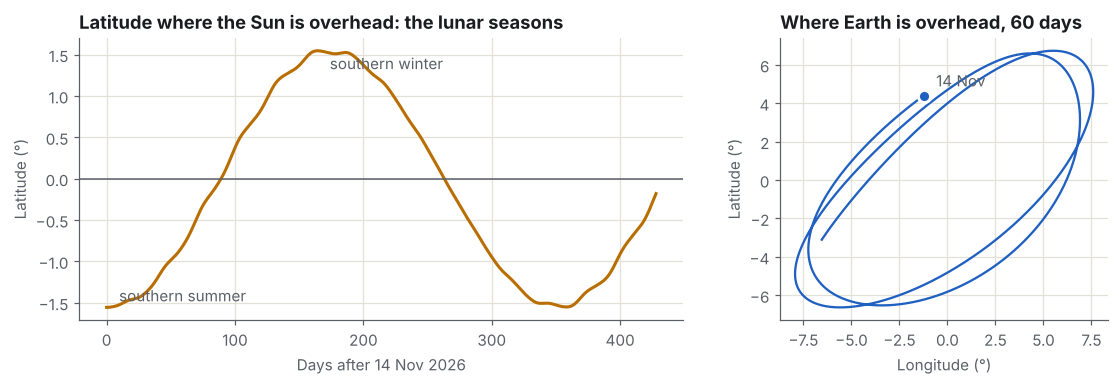

Sun-overhead latitude stays within 1.56°; Earth-overhead point wanders ±6.8° in latitude, ±7.9° in longitude


In [3]:
slat, _ = sub_point(SUNV); elat, elon = sub_point(EARTHV)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(DAYS, slat, color=SUN); ax[0].axhline(0, color=MUTED, lw=1)
ax[0].set(title='Latitude where the Sun is overhead: the lunar seasons', xlabel='Days after 14 Nov 2026', ylabel='Latitude (°)')
ax[0].annotate('southern summer', (DAYS[np.argmin(slat[:4000])], slat[:4000].min()), xytext=(8, 4), textcoords='offset points', color=MUTED)
ax[0].annotate('southern winter', (DAYS[np.argmax(slat[:6000])], slat[:6000].max()), xytext=(8, -12), textcoords='offset points', color=MUTED)
k = slice(0, 60 * 24)
ax[1].plot(elon[k], elat[k], color=EARTH, lw=1.5); ax[1].plot(elon[0], elat[0], 'o', color=EARTH, ms=8, mec='white', mew=2)
ax[1].annotate('14 Nov', (elon[0], elat[0]), xytext=(8, 6), textcoords='offset points', color=MUTED)
ax[1].set(title='Where Earth is overhead, 60 days', xlabel='Longitude (°)', ylabel='Latitude (°)'); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()
print(f'Sun-overhead latitude stays within {abs(slat).max():.2f}°; Earth-overhead point wanders ±{abs(elat).max():.1f}° in latitude, ±{abs(elon).max():.1f}° in longitude')

## 4. Step 2: the view from one spot

From a site we measure two angles for each body:
- **elevation**: how high above a perfectly level horizon (negative means below it),
- **azimuth**: the compass direction (0° north, 90° east).

The site is not at the Moon's centre, so we subtract the site's own position first. That matters for Earth, which is close enough for the view to shift by a quarter of a degree.

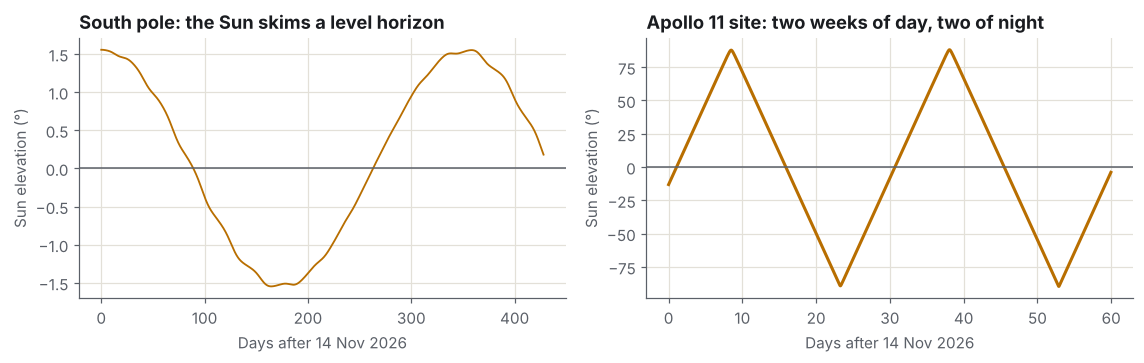

In [4]:
def look(lat, lon, h_m, vec, radius_km):
    """Elevation and azimuth (deg), angular radius (deg) and distance (km) of a body seen from a site."""
    la, lo = np.radians(np.clip(lat, -89.999, 89.999)), np.radians(lon)
    up = np.array([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
    north = np.array([-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)])
    east = np.array([-np.sin(lo), np.cos(lo), 0.0])
    v = np.atleast_2d(vec) - (RM + h_m / 1000) * up
    d = np.linalg.norm(v, axis=1)
    el = np.degrees(np.arcsin(np.clip(v @ up / d, -1, 1)))
    az = np.degrees(np.arctan2(v @ east, v @ north)) % 360
    return el, az, np.degrees(np.arcsin(radius_km / d)), d

pole_el = look(-90, 0, 0, SUNV, RSUN)[0]
a11_el = look(0.6741, 23.4730, 0, SUNV, RSUN)[0]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
ax[0].plot(DAYS, pole_el, color=SUN, lw=1.2); ax[0].axhline(0, color=MUTED, lw=1)
ax[0].set(title='South pole: the Sun skims a level horizon', xlabel='Days after 14 Nov 2026', ylabel='Sun elevation (°)')
ax[1].plot(DAYS[:1440], a11_el[:1440], color=SUN); ax[1].axhline(0, color=MUTED, lw=1)
ax[1].set(title='Apollo 11 site: two weeks of day, two of night', xlabel='Days after 14 Nov 2026', ylabel='Sun elevation (°)')
plt.tight_layout(); plt.show()

### Checking step 1 and 2 against NASA JPL

`truth.json` (in the `build` folder) holds reference angles computed with SPICE from JPL's DE421 ephemeris (script: `build/truth.py`), every 6 hours for six sites. The cell below compares this notebook's Python with those values. The app's JavaScript is checked the same way by `npm test`.

In [5]:
TRUTH_PATH = find('truth.json')
if TRUTH_PATH:
    T = json.load(open(TRUTH_PATH)); worst = 0.0
    for i in range(0, len(T['rows']), 4):                                   # every 24 h is enough for a check
        t = A.Time(((T['t0'] + i * T['step']) - 946728000) / 86400.0)       # seconds since 1970 -> days since 2000
        sun, earth = body_fixed(t)
        for k, (name, lat, lon) in enumerate(T['sites']):
            ref = T['rows'][i][k * 4:k * 4 + 4]
            sel, saz, _, _ = look(lat, lon, 0, sun, RSUN); eel, eaz, _, _ = look(lat, lon, 0, earth, REARTH)
            daz = lambda a, b, el: abs((a - b + 180) % 360 - 180) * np.cos(np.radians(el))
            worst = max(worst, abs(sel[0] - ref[0]), daz(saz[0], ref[1], ref[0]), abs(eel[0] - ref[2]), daz(eaz[0], ref[3], ref[2]))
    print(f'{len(T["rows"]) // 4 + 1} dates x {len(T["sites"])} sites, Nov 2026 to Dec 2028: largest difference from JPL = {worst:.4f}°')
else:
    print('truth.json not found; skipping the comparison.')

792 dates x 6 sites, Nov 2026 to Dec 2028: largest difference from JPL = 0.0042°


## 5. Step 3: the real skyline

The Moon has no air, so nothing bends or blurs the light. The horizon is simply the terrain. NASA's Lunar Orbiter Laser Altimeter (LOLA) measured the heights. The project uses the south-pole model `LDEM_80S_80MPP_ADJ` (one height every 80 m, from 80°S to the pole).

Two products were made from it (script: `build/hires.py`):
- for each listed south-pole site, the **skyline at full 80 m detail**, in 720 directions, for seven mast heights;
- the whole map **averaged to 400 m**, small enough to ship inside the page, used for any other point and for the live shadow map.

In [6]:
DATA = json.load(open(DATA_PATH))

def unpack(d, h, w):
    """Undo the packing used for the web page: base64 -> gzip -> two byte planes -> row-wise differences."""
    raw = np.frombuffer(gzip.decompress(base64.b64decode(d['b64'])), dtype=np.uint8); n = h * w
    delta = (raw[:n].astype(np.uint16) | (raw[n:].astype(np.uint16) << 8)).astype(np.int16).reshape(h, w)
    return np.cumsum(delta, axis=1, dtype=np.int16)

P = DATA['p']; POLAR = unpack(P, P['n'], P['n']).astype(np.float32)     # metres, 400 m per pixel
P_KM, P_HALF, P_N = P['km'], P['half'], P['n']

def polar_xy(lat, lon):
    """Map coordinates (km) in the south polar stereographic projection: +y toward the near side, +x toward 90°E."""
    rho = 2 * RM * np.tan(np.radians(90 + np.asarray(lat, float)) / 2)
    return rho * np.sin(np.radians(lon)), rho * np.cos(np.radians(lon))

def polar_elev(lat, lon):
    """Terrain height (m) south of 80°S, by bilinear interpolation of the 400 m map."""
    x, y = polar_xy(lat, lon)
    c = np.clip((x + P_HALF) / P_KM - 0.5, 0, P_N - 1.001); r = np.clip((P_HALF - y) / P_KM - 0.5, 0, P_N - 1.001)
    c0, r0 = np.floor(c).astype(int), np.floor(r).astype(int); fc, fr = c - c0, r - r0
    return (POLAR[r0, c0] * (1 - fc) + POLAR[r0, c0 + 1] * fc) * (1 - fr) + (POLAR[r0 + 1, c0] * (1 - fc) + POLAR[r0 + 1, c0 + 1] * fc) * fr

NAMES = {'shack': 'Shackleton rim', 'ridge': 'Connecting ridge', 'gerl': 'de Gerlache rim', 'ce7': "Chang'e 7 target", 'mala': 'Malapert Massif',
         'viper': 'Mons Mouton (VIPER)', 'im2': 'IM-2 Athena', 'im1': 'IM-1 Odysseus', 'pole': 'South pole'}
EYES = DATA['hz']['eyes']
SITES = {k: dict(name=NAMES[k], lat=v['lat'], lon=v['lon'], h0=v['h0'],
                 prof=np.frombuffer(base64.b64decode(v['b64']), dtype='<i2').reshape(len(EYES), -1) / 100.0)
         for k, v in DATA['hz']['sites'].items()}
for k, s in SITES.items(): print(f"{s['name']:22s} {s['lat']:9.4f} {s['lon']:10.4f}   height {s['h0']:7.0f} m")

Shackleton rim          -89.7797  -156.3510   height    1737 m
Connecting ridge        -89.4400  -137.0999   height    1958 m
de Gerlache rim         -88.7015   -68.3607   height    1780 m
Chang'e 7 target        -88.8000   123.4000   height    1632 m
Malapert Massif         -85.9907     2.8088   height    5150 m
Mons Mouton (VIPER)     -85.4200    31.6200   height    6419 m
IM-2 Athena             -84.7906    29.1957   height    5322 m
IM-1 Odysseus           -80.1300     1.4400   height    2592 m
South pole              -90.0000     0.0000   height    1291 m


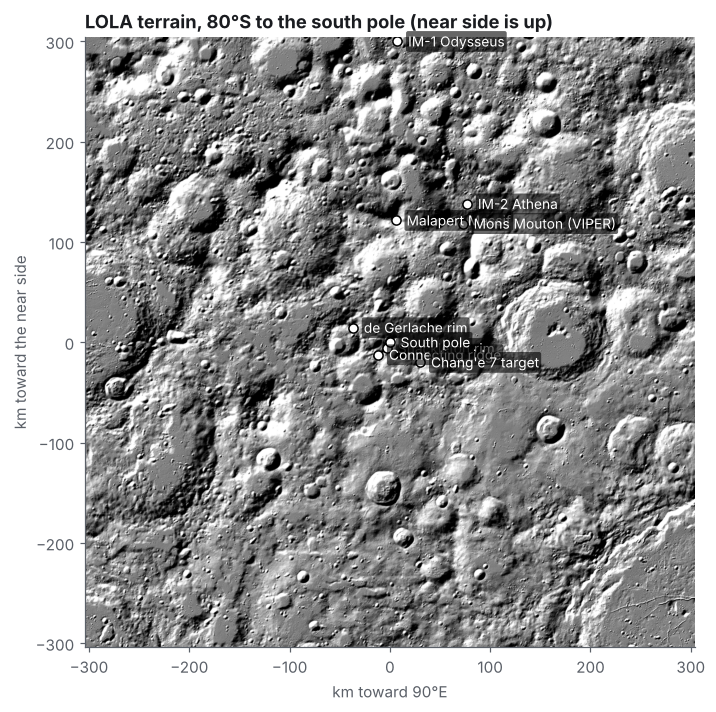

In [7]:
gy, gx = np.gradient(POLAR, P_KM * 1000)
shade = np.clip(0.5 - 1.6 * (gx + gy), 0, 1)                    # light from the upper left, for looks only
fig, ax = plt.subplots(figsize=(7.2, 7.2))
ax.imshow(shade, cmap='gray', extent=[-P_HALF, P_HALF, -P_HALF, P_HALF], vmin=0, vmax=1)
for k, s in SITES.items():
    x, y = polar_xy(s['lat'], s['lon']); ax.plot(x, y, 'o', color='white', mec='black', ms=6)
    ax.annotate(s['name'], (x, y), xytext=(7, 0), textcoords='offset points', color='white', fontsize=9, va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='black', ec='none', alpha=0.6))
ax.set(title='LOLA terrain, 80°S to the south pole (near side is up)', xlabel='km toward 90°E', ylabel='km toward the near side'); ax.grid(False)
plt.show()

### Building a skyline by ray casting

From the site, walk outward along one compass direction. At each step ask: *at what angle do I have to look up (or down) to see this piece of ground?* Because the Moon is round, distant ground drops away, so the formula includes the Moon's radius. Keep the largest angle found. Repeat for every direction. The result is the skyline.

The chart compares the skyline stored at 80 m detail with one ray-cast here from the 400 m map.

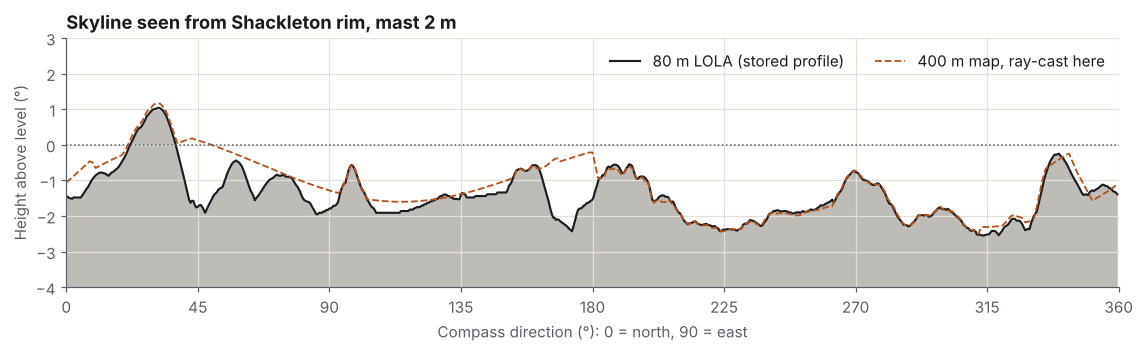

mean difference between the two skylines: 0.28°


In [8]:
def profile_mask(sid, eye=2.0):
    """Skyline (deg) for a listed site from the 80 m profiles, interpolated between the stored mast heights."""
    k = max(0, min(len(EYES) - 2, int(np.searchsorted(EYES, eye, side='right')) - 1))
    f = np.clip((eye - EYES[k]) / (EYES[k + 1] - EYES[k]), 0, 1); p = SITES[sid]['prof']
    return p[k] * (1 - f) + p[k + 1] * f

def mask_at(mask, az):
    """Skyline height at any azimuth, by linear interpolation."""
    n = len(mask); x = (np.asarray(az) % 360) * n / 360; i = np.floor(x).astype(int) % n; f = x - np.floor(x)
    return mask[i] * (1 - f) + mask[(i + 1) % n] * f

def ray_cast_mask(lat, lon, eye=2.0, naz=360):
    """Skyline for any point south of 80°S, ray-cast from the 400 m map (rays stop at the map edge)."""
    d = np.concatenate([np.arange(0.2, 4, 0.2), np.arange(4, 20, 0.4), 20 * 1.035 ** np.arange(0, 82)]); d = d[d <= 320]   # km
    h0 = float(polar_elev(lat, lon)); r0 = RM + (h0 + eye) / 1000
    la = np.radians(max(lat, -89.999)); az = np.radians(np.arange(naz) * 360 / naz)[:, None]; th = (d / RM)[None, :]
    s2 = np.sin(la) * np.cos(th) + np.cos(la) * np.sin(th) * np.cos(az)                 # walk along a great circle
    lat2 = np.degrees(np.arcsin(np.clip(s2, -1, 1)))
    lon2 = lon + np.degrees(np.arctan2(np.sin(az) * np.sin(th) * np.cos(la), np.cos(th) - np.sin(la) * s2))
    r1 = RM + polar_elev(lat2, lon2) / 1000
    return np.degrees(np.arctan2(r1 * np.cos(th) - r0, r1 * np.sin(th))).max(axis=1), h0   # highest angle along each ray

s = SITES['shack']; m80 = profile_mask('shack'); m400, _ = ray_cast_mask(s['lat'], s['lon'])
fig, ax = plt.subplots(figsize=(10.5, 3.3))
ax.fill_between(np.arange(720) / 2, m80, -4, color='#8A857C', alpha=0.55, lw=0)
ax.plot(np.arange(720) / 2, m80, color=INK, lw=1.4, label='80 m LOLA (stored profile)')
ax.plot(np.arange(360), m400, color=WARN, lw=1.2, ls='--', label='400 m map, ray-cast here')
ax.axhline(0, color=MUTED, lw=1, ls=':')
ax.set(title='Skyline seen from Shackleton rim, mast 2 m', xlabel='Compass direction (°): 0 = north, 90 = east', ylabel='Height above level (°)', xlim=(0, 360), ylim=(-4, 3))
ax.set_xticks(range(0, 361, 45)); ax.legend(loc='upper right', ncol=2); plt.tight_layout(); plt.show()
print(f'mean difference between the two skylines: {np.abs(mask_at(m80, np.arange(360)) - m400).mean():.2f}°')

## 6. Step 4: above the skyline or behind it?

Now the two halves meet. For every hour:

- **clearance** = elevation of the body − skyline height in that direction.
- Positive clearance means visible. Negative means hidden.
- The Sun is a disc about half a degree wide, so near the skyline only part of it shows. `disc_frac` gives the visible fraction, which scales the power.

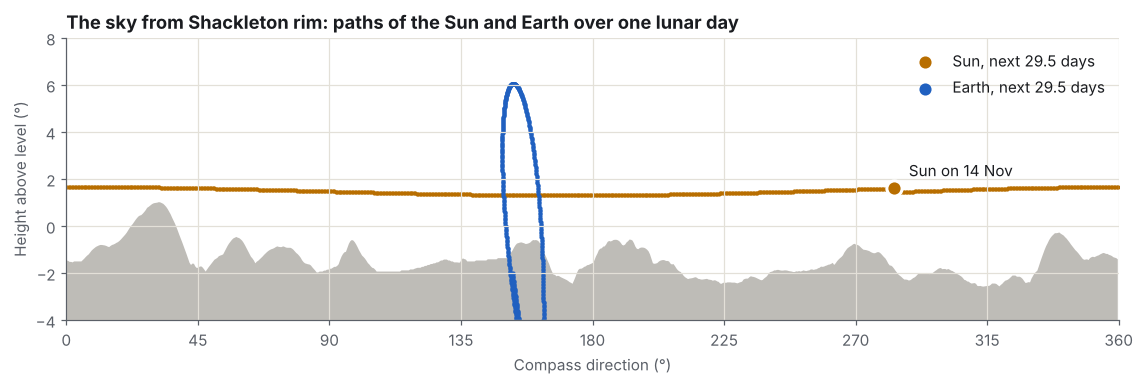

In [9]:
def series(sid, eye=2.0):
    """Hour-by-hour Sun and Earth angles and clearances for a listed site."""
    s = SITES[sid]; m = profile_mask(sid, eye)
    sel, saz, _, sd = look(s['lat'], s['lon'], s['h0'] + eye, SUNV, RSUN)
    eel, eaz, _, _ = look(s['lat'], s['lon'], s['h0'] + eye, EARTHV, REARTH)
    return dict(sun_el=sel, sun_az=saz, sun_clr=sel - mask_at(m, saz), earth_el=eel, earth_az=eaz, earth_clr=eel - mask_at(m, eaz),
                irr=(AU / sd) ** 2, mask=m, n=len(sel))

def disc_frac(clr, rad=0.266):
    """Fraction of the Sun's disc above a straight skyline, given the clearance of its centre (deg)."""
    d = np.clip(np.asarray(clr) / rad, -1, 1)
    return 1 - (np.arccos(d) - d * np.sqrt(1 - d * d)) / np.pi

SER = {k: series(k) for k in SITES}
se = SER['shack']; n = int(29.53 * 24)
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.fill_between(np.arange(720) / 2, se['mask'], -4, color='#8A857C', alpha=0.55, lw=0)
for az, el, col, lab in ((se['sun_az'], se['sun_el'], SUN, 'Sun, next 29.5 days'), (se['earth_az'], se['earth_el'], EARTH, 'Earth, next 29.5 days')):
    ax.scatter(az[:n], el[:n], s=3, color=col, label=lab)
    ax.plot(az[0], el[0], 'o', color=col, ms=10, mec='white', mew=2)
ax.annotate('Sun on 14 Nov', (se['sun_az'][0], se['sun_el'][0]), xytext=(10, 8), textcoords='offset points', color=INK)
ax.annotate('Earth on 14 Nov', (se['earth_az'][0], se['earth_el'][0]), xytext=(10, -14), textcoords='offset points', color=INK)
ax.set(title='The sky from Shackleton rim: paths of the Sun and Earth over one lunar day', xlabel='Compass direction (°)', ylabel='Height above level (°)', xlim=(0, 360), ylim=(-4, 8))
ax.set_xticks(range(0, 361, 45)); ax.legend(loc='upper right', markerscale=4); plt.tight_layout(); plt.show()

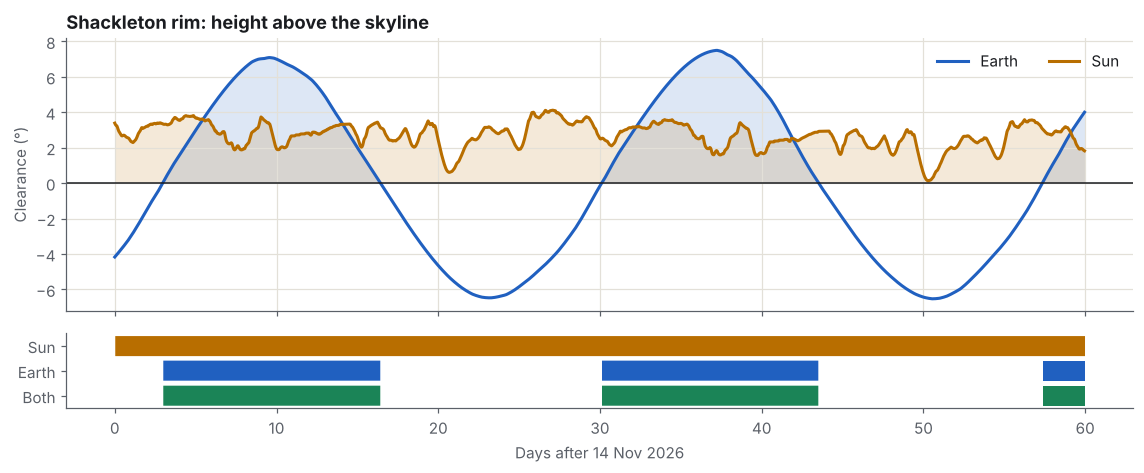

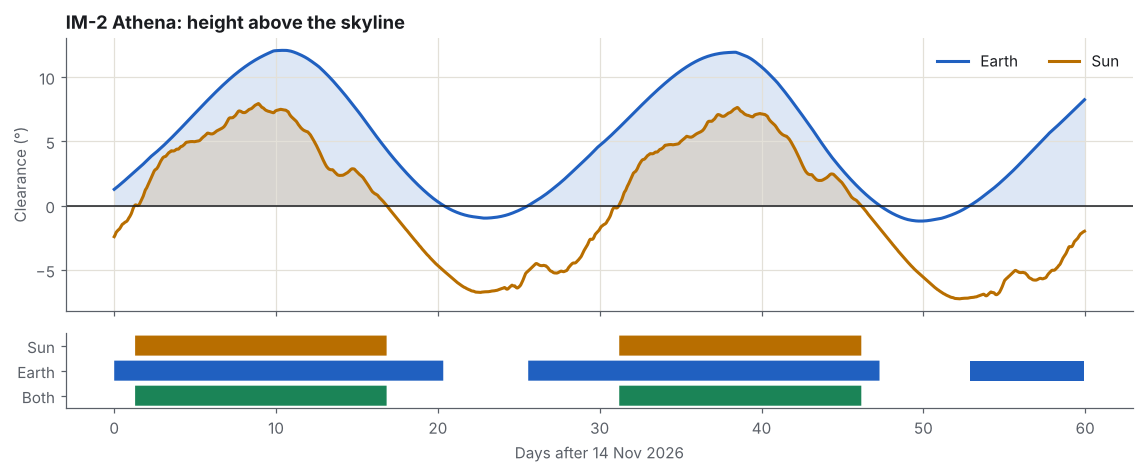

In [10]:
def timeline(sid, days=60):
    se = SER[sid]; k = slice(0, days * 24); x = DAYS[k]
    fig, (a, b) = plt.subplots(2, 1, figsize=(10.5, 4.4), sharex=True, gridspec_kw={'height_ratios': [4, 1.1]})
    for key, col, lab in (('earth_clr', EARTH, 'Earth'), ('sun_clr', SUN, 'Sun')):
        a.plot(x, se[key][k], color=col, label=lab); a.fill_between(x, 0, np.maximum(se[key][k], 0), color=col, alpha=0.15, lw=0)
    a.axhline(0, color=INK, lw=1); a.legend(loc='upper right', ncol=2)
    a.set(title=f"{SITES[sid]['name']}: height above the skyline", ylabel='Clearance (°)')
    for row, (pred, col, lab) in enumerate(((se['sun_clr'][k] > 0, SUN, 'Sun'), (se['earth_clr'][k] > 0, EARTH, 'Earth'), ((se['sun_clr'][k] > 0) & (se['earth_clr'][k] > 0), GO, 'Both'))):
        b.fill_between(x, 2 - row + 0.1, 2 - row + 0.9, where=pred, color=col, lw=0, step='post')
    b.set_yticks([2.5, 1.5, 0.5]); b.set_yticklabels(['Sun', 'Earth', 'Both']); b.set(ylim=(0, 3), xlabel='Days after 14 Nov 2026'); b.grid(False)
    plt.tight_layout(); plt.show()
timeline('shack'); timeline('im2')

In [11]:
import pandas as pd
def longest(mask):
    """Longest run of True, in days (hourly samples)."""
    best = run = 0
    for v in mask:
        run = run + 1 if v else 0; best = max(best, run)
    return best / 24
rows = []
for k, se in SER.items():
    lit = se['sun_clr'][:8760] > 0; link = se['earth_clr'][:8760] > 0
    rows.append({'Site': SITES[k]['name'], 'Sunlit %': round(100 * lit.mean(), 1), 'Earth in view %': round(100 * link.mean(), 1), 'Both %': round(100 * (lit & link).mean(), 1),
                 'Longest sunlit run (d)': round(longest(lit), 1), 'Longest night (d)': round(longest(~lit), 1), 'Longest Earth gap (d)': round(longest(~link), 1)})
print('One year from 14 Nov 2026, mast 2 m, 80 m LOLA skylines')
pd.DataFrame(rows).set_index('Site')

One year from 14 Nov 2026, mast 2 m, 80 m LOLA skylines


,Sunlit %,Earth in view %,Both %,Longest sunlit run (d),Longest night (d),Longest Earth gap (d)
Site,,,,,,
Shackleton rim,86.0,51.0,44.6,79.5,3.5,13.9
Connecting ridge,87.9,52.6,48.9,118.8,11.3,13.4
de Gerlache rim,74.9,56.1,43.6,70.4,8.1,12.8
Chang'e 7 target,56.4,56.7,33.7,19.4,14.9,12.8
Malapert Massif,58.3,100.0,58.3,23.2,17.5,0.0
Mons Mouton (VIPER),48.0,63.5,27.2,22.0,22.1,10.7
IM-2 Athena,46.4,81.4,38.5,15.6,19.1,5.8
IM-1 Odysseus,39.7,100.0,39.7,12.7,19.0,0.0
South pole,28.3,29.0,6.5,13.0,27.7,19.8


## 7. Step 5: would a mission survive?

Sunlight and Earth visibility are only inputs. A mission cares about two things: **does the battery stay above its reserve**, and **is radio silence short enough**.

The model is simple on purpose, and every number can be changed:
- solar power = array output in full Sun × visible fraction of the Sun's disc × a small correction for Sun distance;
- the lander uses one load in sunlight and a smaller one in darkness;
- the battery gains the surplus (at 90% efficiency) and loses the shortfall, hour by hour;
- the mission **fails** if the Sun is not up at landing, the battery drops below the reserve, or (when a direct link is required) Earth is out of view at landing or for longer than the allowed gap.

**Terrain margin.** Terrain data is never perfect. So each plan is tested twice: once as modelled, once with every skyline raised by a margin (0.3° here). A plan that passes only the first test is called **marginal**.

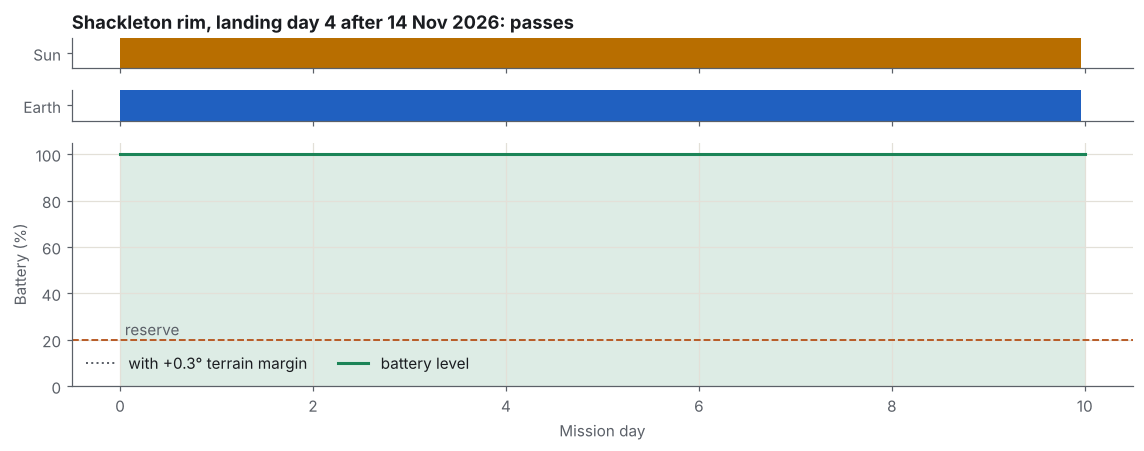

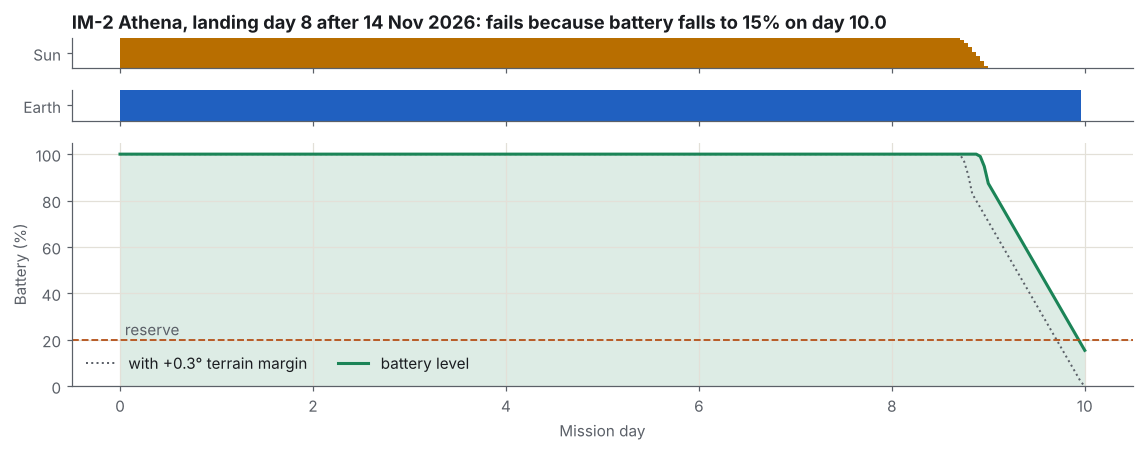

In [12]:
CFG = dict(days=10, peak_w=400, tracking=True, load_sun=180, load_dark=60, cap_wh=2000, min_soc=0.2, charge_eff=0.9,
           need_earth=True, max_gap_h=12, margin=0.3)

def mission(se, i0, cfg=CFG, margin=0.0):
    """Simulate a mission that lands at hourly sample i0. Returns a dict with the verdict and the hour-by-hour traces."""
    want = int(round(cfg['days'] * 24)); n = max(0, min(want, se['n'] - i0)); k = slice(i0, i0 + n)
    f = disc_frac(se['sun_clr'][k] - margin)
    p = cfg['peak_w'] * se['irr'][k] * f * (1 if cfg['tracking'] else np.maximum(0, np.sin(np.radians(se['sun_el'][k]))))
    net = p - np.where(f > 0.02, cfg['load_sun'], cfg['load_dark']); dE = np.where(net > 0, net * cfg['charge_eff'], net)
    link = se['earth_clr'][k] - margin > 0
    E = cfg['cap_wh']; soc = [1.0]; draw = max_draw = 0.0
    for d in dE:
        E = min(cfg['cap_wh'], E + d); soc.append(max(0.0, E / cfg['cap_wh'])); draw = min(0.0, draw + d); max_draw = max(max_draw, -draw)
    soc = np.array(soc); gap = longest(~link) * 24; fails = []
    if n < want: fails.append('the table ends before the mission does')
    if n and f[0] <= 0.5: fails.append('the Sun is not up at landing')
    if cfg['need_earth'] and n and not link[0]: fails.append('no Earth line of sight at landing')
    if soc.min() < cfg['min_soc']: fails.append(f'battery falls to {100 * soc.min():.0f}% on day {soc.argmin() / 24:.1f}')
    if cfg['need_earth'] and gap > cfg['max_gap_h']: fails.append(f'Earth is out of view for {gap:.0f} h (limit {cfg["max_gap_h"]} h)')
    return dict(ok=not fails, fails=fails, soc=soc, sun=f, link=link, min_soc=soc.min(), gap_h=gap, batt_need_wh=max_draw / (1 - cfg['min_soc']))

def verdict(se, i0, cfg=CFG):
    """2 = passes even with the terrain margin, 1 = passes only without it, 0 = fails."""
    if not mission(se, i0, cfg)['ok']: return 0
    return 2 if mission(se, i0, cfg, cfg['margin'])['ok'] else 1
LABEL = {2: 'passes', 1: 'marginal', 0: 'fails'}

def survival(sid, day, cfg=CFG):
    """The mission survival timeline: sunlight, Earth line of sight and battery level."""
    se = SER[sid]; r = mission(se, day * 24, cfg); rm = mission(se, day * 24, cfg, cfg['margin']); x = np.arange(len(r['sun'])) / 24
    fig, (a, b, c) = plt.subplots(3, 1, figsize=(10.5, 4.2), sharex=True, gridspec_kw={'height_ratios': [0.5, 0.5, 4]})
    a.fill_between(x, 0, r['sun'], color=SUN, lw=0, step='post'); b.fill_between(x, 0, 1, where=r['link'], color=EARTH, lw=0, step='post')
    for axx, lab in ((a, 'Sun'), (b, 'Earth')): axx.set_yticks([0.5]); axx.set_yticklabels([lab]); axx.set_ylim(0, 1); axx.grid(False)
    xs = np.arange(len(r['soc'])) / 24
    c.plot(xs, 100 * rm['soc'], color=MUTED, lw=1.3, ls=':', label=f"with +{cfg['margin']}° terrain margin")
    c.plot(xs, 100 * r['soc'], color=GO, label='battery level'); c.fill_between(xs, 0, 100 * r['soc'], color=GO, alpha=0.15, lw=0)
    c.axhline(100 * cfg['min_soc'], color=WARN, lw=1.2, ls='--'); c.annotate('reserve', (0.05, 100 * cfg['min_soc'] + 2), color=MUTED)
    c.set(ylim=(0, 105), ylabel='Battery (%)', xlabel='Mission day'); c.legend(loc='lower left', ncol=2)
    state = verdict(se, day * 24, cfg)
    a.set_title(f"{SITES[sid]['name']}, landing day {day} after 14 Nov 2026: {LABEL[state]}" + ('' if r['ok'] else ' because ' + '; '.join(r['fails'])))
    plt.tight_layout(); plt.show()

survival('shack', 4)                                  # the default plan in the app: 18 Nov 2026
bad = next(d for d in range(120) if any('battery' in f for f in mission(SER['im2'], d * 24)['fails']) and disc_frac(SER['im2']['sun_clr'][d * 24]) > 0.5)
survival('im2', bad)                                  # a landing that starts in sunlight but runs into the lunar night

### The landing-date calendar

Run the same test for every possible landing day and every site, and a pattern appears: at the pole there are only a few good landing days per month, and they move with the seasons. This is the picture of "what a schedule slip costs".

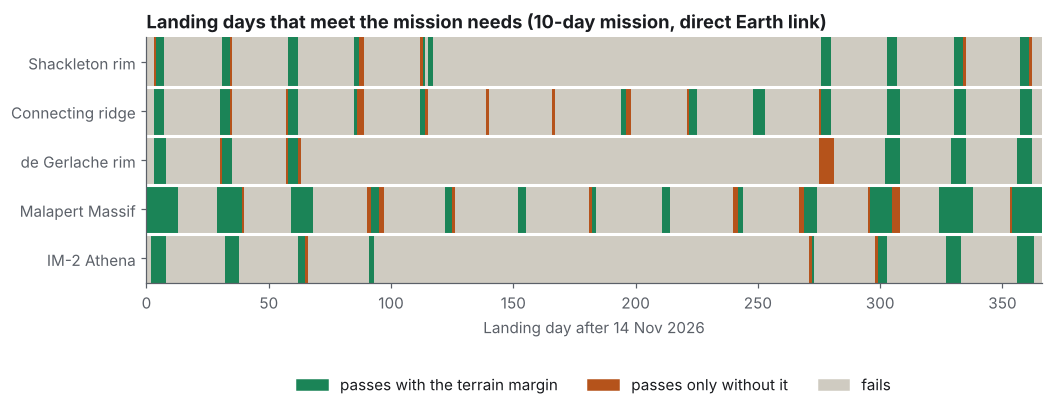

{'Shackleton rim': 31, 'Connecting ridge': 44, 'de Gerlache rim': 31, 'Malapert Massif': 88, 'IM-2 Athena': 35} good landing days out of 366


In [13]:
show = ['shack', 'ridge', 'gerl', 'mala', 'im2']; ND = 366
cal = np.array([[verdict(SER[k], d * 24) for d in range(ND)] for k in show])
fig, ax = plt.subplots(figsize=(10.5, 2.9))
ax.imshow(cal, aspect='auto', cmap=ListedColormap([FAIL_GREY, WARN, GO]), vmin=0, vmax=2, interpolation='nearest', extent=[0, ND, len(show), 0])
ax.set_yticks(np.arange(len(show)) + 0.5); ax.set_yticklabels([SITES[k]['name'] for k in show]); ax.grid(False)
for y in range(1, len(show)): ax.axhline(y, color='white', lw=2)
ax.set(title='Landing days that meet the mission needs (10-day mission, direct Earth link)', xlabel='Landing day after 14 Nov 2026')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (GO, WARN, FAIL_GREY)], labels=['passes with the terrain margin', 'passes only without it', 'fails'], loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.show()
print({SITES[k]['name']: int((cal[i] == 2).sum()) for i, k in enumerate(show)}, 'good landing days out of', ND)

### Mission Rescue

The plan was to land at Shackleton rim on day 4 (18 Nov 2026). The landing slips by 14 days. Is the mission still possible, and if not, where and when is the nearest option that works? The search tries every listed south-pole site, every 6 hours, for up to 21 days after the slipped date.

In [14]:
def rescue(plan_site='shack', plan_day=4, slip=14, flex=21, cfg=CFG):
    i_slip = (plan_day + slip) * 24; out = []
    print(f"As planned ({SITES[plan_site]['name']}, day {plan_day}): {LABEL[verdict(SER[plan_site], plan_day * 24, cfg)]}")
    r = mission(SER[plan_site], i_slip, cfg)
    print(f"After a {slip}-day slip, same site: {LABEL[verdict(SER[plan_site], i_slip, cfg)]}" + ('' if r['ok'] else ' because ' + '; '.join(r['fails'])))
    for k, se in SER.items():
        best = None
        for i in range(i_slip, i_slip + flex * 24 + 1, 6):
            v = verdict(se, i, cfg)
            if best is None or v > best[0]: best = (v, i)
            if v == 2: break
        v, i = best; r = mission(se, i, cfg)
        out.append({'Site': SITES[k]['name'], 'Verdict': LABEL[v], 'Land on day': round(i / 24, 2) if v else None, 'Extra wait (d)': round((i - i_slip) / 24, 2) if v else None,
                    'Lowest battery %': round(100 * r['min_soc']), 'Longest link gap (h)': round(r['gap_h']), '_v': v, '_i': i if v else 1e9})
    df = pd.DataFrame(out).sort_values(['_v', '_i'], ascending=[False, True]).drop(columns=['_v', '_i']).reset_index(drop=True); df.index += 1
    return df
rescue()

As planned (Shackleton rim, day 4): passes
After a 14-day slip, same site: fails because no Earth line of sight at landing; Earth is out of view for 240 h (limit 12 h)


,Site,Verdict,Land on day,Extra wait (d),Lowest battery %,Longest link gap (h)
1,Malapert Massif,passes,28.50,10.50,100,0
2,Connecting ridge,passes,30.00,12.00,100,0
3,Chang'e 7 target,passes,30.00,12.00,100,0
4,de Gerlache rim,passes,30.25,12.25,100,0
5,Shackleton rim,passes,30.50,12.50,100,0
6,IM-2 Athena,passes,31.50,13.50,100,0
7,IM-1 Odysseus,passes,34.75,16.75,100,0
8,Mons Mouton (VIPER),fails,NaN,NaN,100,240
9,South pole,fails,NaN,NaN,0,240


**Reading the table.** The 14-day slip really costs more than 14 days at the original site, because the next window with both Sun and Earth opens later. Changing site recovers part of that.

## 8. Going further: landing risk with a Monte Carlo simulation

Everything so far assumed the lander comes down **exactly** on the chosen point, at the chosen minute, on terrain that is known perfectly. None of that is true in practice. At the south pole a few hundred metres can be the difference between a sunlit ridge and a dark slope.

A **Monte Carlo simulation** deals with this by brute force:
1. Roll the dice: pick a touchdown point a little off target, a landing time a little early or late, terrain a little higher or lower than the map says, and hardware a little better or worse than planned.
2. Run the mission test from step 5 with those numbers. Record pass or fail.
3. Repeat thousands of times. The share of passes is the **chance of success**.

To keep it fast, the area around the target is cut into a grid of cells. Each cell gets its own skyline (ray-cast from the 400 m map) and its own batch of random missions. The chance of success for a given aim point is then the average over the cells, weighted by how likely the lander is to come down in each one.

The app does the same thing in its "Landing risk" panel, with one difference: near the listed sites it ray-casts from finer 80 m terrain, while this notebook uses the 400 m map only. Finer terrain shows a narrower safe strip along the rim, so the app reports a lower chance of success than the numbers here.

In [15]:
def site_series(lat, lon, i_start, n, eye=2.0):
    """Sun and Earth clearances for any point south of 80 S, for the hourly samples [i_start, i_start + n)."""
    m, h0 = ray_cast_mask(lat, lon, eye, naz=180); k = slice(i_start, i_start + n)
    sel, saz, _, sd = look(lat, lon, h0 + eye, SUNV[k], RSUN); eel, eaz, _, _ = look(lat, lon, h0 + eye, EARTHV[k], REARTH)
    return dict(sun_el=sel, sun_clr=sel - mask_at(m, saz), earth_clr=eel - mask_at(m, eaz), irr=(AU / sd) ** 2, n=n)

def success_map(sid='shack', day=5, half_km=1.5, n=17, K=24, time_h=6, cfg=CFG, seed=20261114):
    """For each touchdown cell around a site, the share of K random missions that meet the needs."""
    rng = np.random.default_rng(seed); s = SITES[sid]; sp = 2 * half_km / (n - 1)
    J = int(np.ceil(4 * time_h / 3)) + 1; want = cfg['days'] * 24; start = day * 24 - J; length = 2 * J + want + 1
    x0, y0 = polar_xy(s['lat'], s['lon']); P = np.zeros((n, n))
    for iy in range(n):
        for ix in range(n):
            x = x0 + (ix - (n - 1) / 2) * sp; y = y0 + ((n - 1) / 2 - iy) * sp; rho = np.hypot(x, y)
            se = site_series(max(-89.999, -90 + 2 * np.degrees(np.arctan(rho / (2 * RM)))), np.degrees(np.arctan2(x, y)), start, length)
            ok = 0
            for _ in range(K):
                c = dict(cfg); l = max(0.0, 1 + 0.05 * rng.standard_normal())                 # loads: 5% spread
                c['peak_w'] = cfg['peak_w'] * max(0.0, 1 + 0.05 * rng.standard_normal())      # array output: 5%
                c['load_sun'] = cfg['load_sun'] * l; c['load_dark'] = cfg['load_dark'] * l
                c['cap_wh'] = cfg['cap_wh'] * max(0.1, 1 + 0.03 * rng.standard_normal())      # battery: 3%
                i = int(np.clip(J + round(time_h / 3 * rng.standard_normal()), 0, length - want))   # landing time
                ok += mission(se, i, c, margin=cfg['margin'] / 2 * rng.standard_normal())['ok']      # terrain error
            P[iy, ix] = ok / K
    return P, sp

def aim_prob(P, sp, accuracy_m, ax=None, ay=None):
    """Chance of success when aiming at cell (ax, ay), for a lander that comes down within accuracy_m (3 sigma)."""
    n = P.shape[0]; ax = (n - 1) / 2 if ax is None else ax; ay = (n - 1) / 2 if ay is None else ay
    R = accuracy_m / 1000; sigma = R / 3; yy, xx = np.mgrid[0:n, 0:n]; d2 = ((xx - ax) ** 2 + (yy - ay) ** 2) * sp * sp
    w = np.exp(-d2 / (2 * sigma ** 2)) * (d2 <= R * R + 1e-9)
    return float((w * P).sum() / w.sum())

PMAP, SP = success_map('shack', day=5)
print(f'{PMAP.size * 24:,} simulated missions around Shackleton rim, landing on day 5')
for acc in (200, 500, 1000): print(f'  landing accuracy {acc:5d} m (3 sigma): chance of success {100 * aim_prob(PMAP, SP, acc):.0f}%')

6,936 simulated missions around Shackleton rim, landing on day 5
  landing accuracy   200 m (3 sigma): chance of success 98%
  landing accuracy   500 m (3 sigma): chance of success 67%
  landing accuracy  1000 m (3 sigma): chance of success 32%


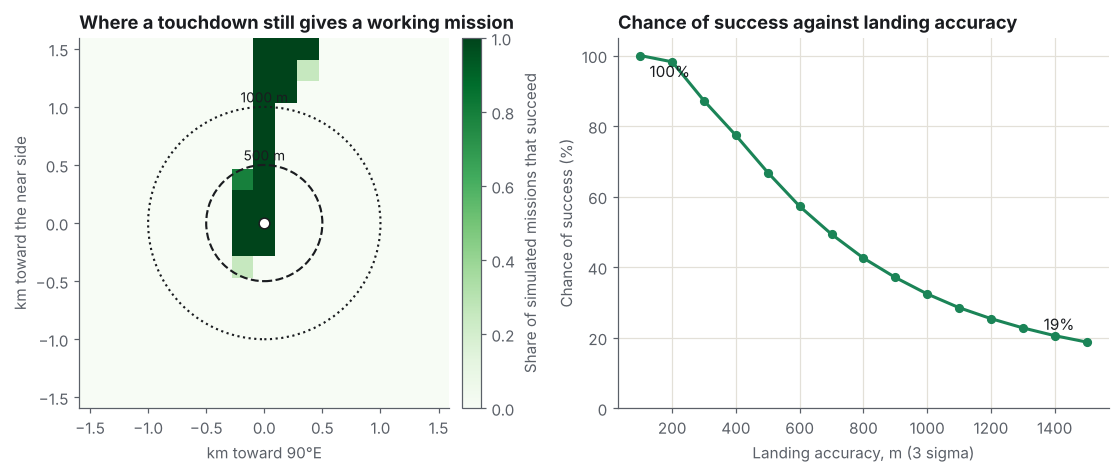

In [16]:
half = SP * (PMAP.shape[0] - 1) / 2 + SP / 2
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={'width_ratios': [1, 1.15]})
im = ax[0].imshow(PMAP, cmap='Greens', vmin=0, vmax=1, extent=[-half, half, -half, half])
for acc, ls in ((500, '--'), (1000, ':')):
    ax[0].add_patch(plt.Circle((0, 0), acc / 1000, fill=False, ec=INK, ls=ls, lw=1.4))
    ax[0].annotate(f'{acc} m', (0, acc / 1000), xytext=(0, 3), textcoords='offset points', ha='center', color=INK, fontsize=9)
ax[0].plot(0, 0, 'o', color='white', mec=INK, ms=7); ax[0].grid(False)
ax[0].set(title='Where a touchdown still gives a working mission', xlabel='km toward 90°E', ylabel='km toward the near side')
plt.colorbar(im, ax=ax[0], fraction=0.046, pad=0.03, label='Share of simulated missions that succeed')
accs = np.arange(100, 1501, 100); probs = [100 * aim_prob(PMAP, SP, a) for a in accs]
ax[1].plot(accs, probs, color=GO, marker='o', ms=5)
ax[1].set(title='Chance of success against landing accuracy', xlabel='Landing accuracy, m (3 sigma)', ylabel='Chance of success (%)', ylim=(0, 105))
ax[1].annotate(f'{probs[0]:.0f}%', (accs[0], probs[0]), xytext=(6, -14), textcoords='offset points', color=INK)
ax[1].annotate(f'{probs[-1]:.0f}%', (accs[-1], probs[-1]), xytext=(-8, 8), textcoords='offset points', color=INK, ha='right')
plt.tight_layout(); plt.show()

**Reading the charts.** On the left, only a narrow band along the crater rim works: step off the crest and either the Sun or the Earth drops behind the ground. On the right, the chance of success falls as the landing gets less precise. The simple pass or fail verdict hid this completely. It is why rim sites call for precision landing.

## 9. Limits to keep in mind
- Power is geometry only. Temperature, dust, how far the array can turn, and ageing are not modelled.
- "Earth in view" means a straight line to Earth's centre clears the terrain. Antenna pointing, signal strength and ground-station schedules are not modelled.
- Samples are hourly, so a window shorter than an hour can be missed.
- Only the listed south-pole sites use the full 80 m skyline. Other points, and the whole landing-risk analysis, use coarser terrain.
- The random spreads in the landing-risk analysis are assumptions, not measured values.
- Coordinates of planned missions are published targets and may change.

## Appendix: the app's source files
The cells below print the JavaScript that runs in the browser, so you can read it here. `engine.js`, `terrain.js` and `analysis.js` do the same things as the Python above. `app.js` draws the screen.

In [17]:
from IPython.display import Code, display
p = find('engine.js')
display(Code(filename=p, language='javascript')) if p else print('engine.js not found next to this notebook')

/* Ephemeris + geometry engine. Needs global Astronomy (astronomy-engine). */
const Eng = (() => {
  const A = (typeof Astronomy !== 'undefined') ? Astronomy : require('astronomy-engine');
  const D2R = Math.PI / 180, R2D = 180 / Math.PI, AU = 149597870.7;
  const RM = 1737.4, RSUN = 695700, REARTH = 6378.137;

  // Sun and Earth position vectors (km) in the Moon body-fixed frame at a JS Date / ms.
  function bodyFixed(ms) {
    const t = A.MakeTime(new Date(ms));
    const m = A.GeoMoon(t);                       // geocentric Moon, J2000 equatorial, AU
    const s = A.GeoVector(A.Body.Sun, t, true);   // geocentric Sun, light-time + aberration
    const ax = A.RotationAxis(A.Body.Moon, t);    // IAU lunar pole + prime meridian angle
    const a0 = ax.ra * 15 * D2R, W = ax.spin * D2R;
    const p = [ax.north.x, ax.north.y, ax.north.z];
    const N = [-Math.sin(a0), Math.cos(a0), 0];   // node of lunar equator on J2000 equator
    const M = cross(p, N);
    const cw = Math.cos(W), sw = Math.sin(W);
    const X = [N[0]*cw + M[0]*sw, N[1]*cw + M[1]*sw, N[2]*cw + M[2]*sw];
    const Y = cross(p, X);
    const sv = [(s.x - m.x) * AU, (s.y - m.y) * AU, (s.z - m.z) * AU];
    const ev = [-m.x * AU, -m.y * AU, -m.z * AU];
    return {
      sun: [dot(sv, X), dot(sv, Y), dot(sv, p)],
      earth: [dot(ev, X), dot(ev, Y), dot(ev, p)],
      // Earth-fixed needs for ground-station check are computed separately
    };
  }
  const dot = (a, b) => a[0]*b[0] + a[1]*b[1] + a[2]*b[2];
  const cross = (a, b) => [a[1]*b[2]-a[2]*b[1], a[2]*b[0]-a[0]*b[2], a[0]*b[1]-a[1]*b[0]];

  // Site basis in the body-fixed frame.
  function siteBasis(lat, lon, h_km) {
    const la = lat * D2R, lo = lon * D2R, cl = Math.cos(la), sl = Math.sin(la), co = Math.cos(lo), so = Math.sin(lo);
    return { up: [cl*co, cl*so, sl], north: [-sl*co, -sl*so, cl], east: [-so, co, 0], r: RM + (h_km || 0) };
  }
  // Topocentric elevation/azimuth (deg) and angular radius (deg) of a body vector seen from the site.
  function look(b, v, radius_km) {
    const x = v[0] - b.r*b.up[0], y = v[1] - b.r*b.up[1], z = v[2] - b.r*b.up[2];
    const d = Math.hypot(x, y, z);
    const u = (x*b.up[0] + y*b.up[1] + z*b.up[2]) / d;
    const n = (x*b.north[0] + y*b.north[1] + z*b.north[2]) / d;
    const e = (x*b.east[0] + y*b.east[1] + z*b.east[2]) / d;
    let az = Math.atan2(e, n) * R2D; if (az < 0) az += 360;
    return { el: Math.asin(Math.max(-1, Math.min(1, u))) * R2D, az, rad: Math.asin(radius_km / d) * R2D, dist: d };
  }
  // Sub-point (lat, lon deg) of a body-fixed vector.
  function subPoint(v) {
    const d = Math.hypot(v[0], v[1], v[2]);
    return { lat: Math.asin(v[2] / d) * R2D, lon: Math.atan2(v[1], v[0]) * R2D };
  }

  // Cached table of body-fixed vectors: Float64Array [sx,sy,sz,ex,ey,ez] per step.
  function makeTable(t0, stepMs, n) {
    const a = new Float64Array(n * 6);
    for (let i = 0; i < n; i++) {
      const b = bodyFixed(t0 + i * stepMs);
      a.set(b.sun, i*6); a.set(b.earth, i*6 + 3);
    }
    return { t0, stepMs, n, a };
  }

  // Fraction of a disc (centre elevation el, radius r) above a straight horizon at elevation hz.
  function discFrac(el, r, hz) {
    const d = (el - hz) / r;
    if (d >= 1) return 1; if (d <= -1) return 0;
    return 1 - (Math.acos(d) - d * Math.sqrt(1 - d*d)) / Math.PI;
  }

  // Ground stations (Deep Space Network): elevation of the Moon from each complex.
  const DSN = [
    { name: 'Goldstone', lat: 35.4267, lon: -116.8900 },
    { name: 'Madrid', lat: 40.4314, lon: -4.2481 },
    { name: 'Canberra', lat: -35.4014, lon: 148.9817 },
  ];
  function dsnView(ms) {
    const t = A.MakeTime(new Date(ms));
    return DSN.map(s => {
      const obs = new A.Observer(s.lat, s.lon, 900);
      const eq = A.Equator(A.Body.Moon, t, obs, true, true);
      const h = A.Horizon(t, obs, eq.ra, eq.dec, 'normal');
      return { name: s.name, el: h.altitude };
    });
  }
  return { bodyFixed, siteBasis, look, subPoint, makeTable, discFrac, ds

In [18]:
from IPython.display import Code, display
p = find('terrain.js')
display(Code(filename=p, language='javascript')) if p else print('terrain.js not found next to this notebook')

/* Terrain: LOLA-derived elevation grids, sampling, horizon masks. */
const Terrain = (() => {
  const D2R = Math.PI / 180, R2D = 180 / Math.PI, RM = 1737.4;
  const grids = {}, profiles = { sites: {}, eyes: [], naz: 0 }, patches = {}; let polar = null, focus = null;
  const CAPLAT = -80.02;
  function unpack(bytes, h, w) {           // two byte planes of row-delta int16 -> Int16Array metres
    const n = h * w, out = new Int16Array(n);
    for (let r = 0; r < h; r++) {
      let acc = 0;
      for (let c = 0; c < w; c++) {
        const i = r * w + c;
        let v = bytes[i] | (bytes[n + i] << 8); if (v & 0x8000) v -= 0x10000;
        acc = (c === 0) ? v : ((acc + v + 0x8000) & 0xFFFF) - 0x8000;
        out[i] = acc;
      }
    }
    return out;
  }
  async function gunzipB64(b64) {
    if (typeof DecompressionStream === 'undefined') {          // Node (tests)
      return new Uint8Array(require('zlib').gunzipSync(Buffer.from(b64, 'base64')));
    }
    const bin = atob(b64), u = new Uint8Array(bin.length);
    for (let i = 0; i < bin.length; i++) u[i] = bin.charCodeAt(i);
    const st = new Blob([u]).stream().pipeThrough(new DecompressionStream('gzip'));
    return new Uint8Array(await new Response(st).arrayBuffer());
  }
  async function load(data) {
    for (const k of ['g', 's', 'n']) {
      const d = data[k];
      grids[k] = { h: d.h, w: d.w, a: unpack(await gunzipB64(d.b64), d.h, d.w) };
    }
    if (data.p) { const d = data.p; polar = { n: d.n, km: d.km, half: d.half, a: unpack(await gunzipB64(d.b64), d.n, d.n) }; }
    if (data.patch) for (const id in data.patch) {
      const o = {}; for (const k of ['a', 'b']) { const d = data.patch[id][k]; if (d) o[k] = { n: d.n, km: d.km, x: d.x, y: d.y, a: unpack(await gunzipB64(d.b64), d.n, d.n) }; }
      patches[id] = o;
    }
    if (data.hz) {
      const dec = (typeof atob === 'undefined') ? b => new Uint8Array(Buffer.from(b, 'base64')) : b => { const t = atob(b), u = new Uint8Array(t.length); for (let i = 0; i < t.length; i++) u[i] = t.charCodeAt(i); return u; };
      profiles.eyes = data.hz.eyes; profiles.naz = data.hz.naz;
      for (const id in data.hz.sites) { const q = data.hz.sites[id], u = dec(q.b64); profiles.sites[id] = { lat: q.lat, lon: q.lon, h0: q.h0, a: new Int16Array(u.buffer, u.byteOffset, u.length / 2) }; }
    }
  }
  // 80 m LOLA horizon profile for a curated site, interpolated between precomputed eye heights.
  function profileMask(id, eye_m) {
    const q = profiles.sites[id]; if (!q) return null;
    const ey = profiles.eyes, n = profiles.naz; if (eye_m > ey[ey.length - 1]) return null;
    let k = 0; while (k < ey.length - 2 && eye_m > ey[k + 1]) k++;
    const f = Math.max(0, Math.min(1, (eye_m - ey[k]) / (ey[k + 1] - ey[k]))), mask = new Float32Array(n);
    for (let i = 0; i < n; i++) mask[i] = (q.a[k * n + i] * (1 - f) + q.a[(k + 1) * n + i] * f) / 100;
    return { mask, h0: q.h0, tier: 'LOLA 80 m' };
  }
  // Fine patches: choose the listed site nearest to (lat, lon); its 80 m and 240 m patches then take priority in elevXY.
  function setFocus(lat, lon) {
    focus = null; if (!polar || lat > -79.9) return null;
    const rho = 2 * RM * Math.tan((90 + lat) / 2 * D2R), x = rho * Math.sin(lon * D2R), y = rho * Math.cos(lon * D2R); let best = 14;
    for (const id in patches) { const q = patches[id].a; if (!q) continue; const d = Math.hypot(q.x + q.n * q.km / 2 - x, q.y - q.n * q.km / 2 - y); if (d < best) { best = d; focus = patches[id]; } }
    return focus;
  }
  function patchAt(q, x, y) {
    const c = (x - q.x) / q.km, r = (q.y - y) / q.km; if (c < 0 || r < 0 || c > q.n - 1.001 || r > q.n - 1.001) return NaN;
    const c0 = Math.floor(c), r0 = Math.floor(r), fc = c - c0, fr = r - r0, a = q.a, i = r0 * q.n + c0;
    return (a[i] * (1 - fc) + a[i + 1] * fc) * (1 - fr) + (a[i + q.n] * (1 - fc) + a[i + q.n + 1] * fc) * fr;
  }
  // Smooth (Catmull-Rom) sampling of a patch, for drawing: bilinear facets show up as stair-steps on silhouettes.

In [19]:
from IPython.display import Code, display
p = find('analysis.js')
display(Code(filename=p, language='javascript')) if p else print('analysis.js not found next to this notebook')

/* Per-site time series and window statistics on top of Eng + Terrain. */
const Ana = (() => {
  const E = (typeof Eng !== 'undefined') ? Eng : require('./engine.js');
  const T = (typeof Terrain !== 'undefined') ? Terrain : require('./terrain.js');
  const maskCache = new Map();
  function siteMask(site, eye) {
    const k = (site.id || '') + ',' + site.lat.toFixed(4) + ',' + site.lon.toFixed(4) + ',' + eye;
    let m = maskCache.get(k);
    if (!m) {
      m = (site.id && T.profileMask(site.id, eye)) || T.horizonMask(site.lat, site.lon, eye);
      let lo = 99, hi = -99; for (const v of m.mask) { if (v < lo) lo = v; if (v > hi) hi = v; } m.lo = lo; m.hi = hi;
      if (maskCache.size > 80) maskCache.clear(); maskCache.set(k, m);
    }
    return m;
  }
  // Sun and Earth state at one instant from precomputed body-fixed vectors.
  function stateFrom(site, eye, sun, earth) { return stateWith(site, eye, siteMask(site, eye), sun, earth); }
  // Same, with the horizon mask supplied by the caller.
  function stateWith(site, eye, m, sun, earth) {
    const lat = Math.max(-89.999, Math.min(89.999, site.lat));
    const b = E.siteBasis(lat, site.lon, (m.h0 + eye) / 1000);
    const s = E.look(b, sun, E.RSUN), e = E.look(b, earth, E.REARTH);
    const hs = T.maskAt(m.mask, s.az), he = T.maskAt(m.mask, e.az);
    return { sunEl: s.el, sunAz: s.az, sunRad: s.rad, sunHz: hs, sunClr: s.el - hs, sunFrac: E.discFrac(s.el, s.rad, hs),
             earthEl: e.el, earthAz: e.az, earthRad: e.rad, earthHz: he, earthClr: e.el - he, h0: m.h0, irr: (149597870.7 / s.dist) * (149597870.7 / s.dist) };
  }
  function series(site, eye, tab) { return seriesAt(site, eye, siteMask(site, eye), tab, 0, tab.n); }
  // Series for samples [start, start + n) of a table, with a caller-supplied horizon mask.
  function seriesAt(site, eye, m, tab, start, n) {
    const a = tab.a.subarray(start * 6, (start + n) * 6);
    const o = { n, sunEl: new Float32Array(n), sunAz: new Float32Array(n), sunClr: new Float32Array(n), sunFrac: new Float32Array(n),
                earthEl: new Float32Array(n), earthAz: new Float32Array(n), earthClr: new Float32Array(n), irr: new Float32Array(n) };
    const sv = [0, 0, 0], ev = [0, 0, 0];
    for (let i = 0; i < n; i++) {
      sv[0] = a[i*6]; sv[1] = a[i*6+1]; sv[2] = a[i*6+2]; ev[0] = a[i*6+3]; ev[1] = a[i*6+4]; ev[2] = a[i*6+5];
      const s = stateWith(site, eye, m, sv, ev);
      o.sunEl[i] = s.sunEl; o.sunAz[i] = s.sunAz; o.sunClr[i] = s.sunClr; o.sunFrac[i] = s.sunFrac;
      o.earthEl[i] = s.earthEl; o.earthAz[i] = s.earthAz; o.earthClr[i] = s.earthClr; o.irr[i] = s.irr;
    }
    return o;
  }
  // Next zero crossing of arr after fractional index x; returns {idx, rising} or null.
  function nextCross(arr, x, n) {
    let i = Math.floor(x); if (i < 0) i = 0;
    const f = x - i;
    let prev = (i + 1 < n) ? arr[i] * (1 - f) + arr[i + 1] * f : arr[Math.min(i, n - 1)];
    let px = x;
    for (let j = i + 1; j < n; j++) {
      const v = arr[j];
      if ((prev > 0) !== (v > 0)) return { idx: px + (j - px) * (prev / (prev - v)), rising: v > 0 };
      prev = v; px = j;
    }
    return null;
  }
  // Statistics over samples [i0, i1).
  function stats(se, i0, i1, stepH, needEarth) {
    let lit = 0, link = 0, both = 0, pTrack = 0, pFlat = 0, runL = 0, maxL = 0, runD = 0, maxD = 0, runO = 0, maxO = 0, runB = 0, maxB = 0;
    const n = i1 - i0;
    for (let i = i0; i < i1; i++) {
      const L = se.sunClr[i] > 0, K = se.earthClr[i] > 0, B = L && (K || !needEarth);
      if (L) { lit++; runL++; if (runL > maxL) maxL = runL; runD = 0; } else { runD++; if (runD > maxD) maxD = runD; runL = 0; }
      if (K) { link++; runO = 0; } else { runO++; if (runO > maxO) maxO = runO; }
      if (B) { both++; runB++; if (runB > maxB) maxB = runB; } else runB = 0;
      pTrack += se.sunFrac[i];
      pFlat += se.sunFrac[i] * Math.max(0, Math.sin(se.sunEl[i] * Math.PI / 180));
    }
    const d = stepH / 24;
    return { litPct: 100 * lit / n, li

In [20]:
from IPython.display import Code, display
p = find('app.js')
display(Code(filename=p, language='javascript')) if p else print('app.js not found next to this notebook')

(async function () {
  const $ = id => document.getElementById(id);
  const DAY = 86400e3, HOUR = 3600e3, D2R = Math.PI / 180, R2D = 180 / Math.PI, RM = Eng.RM;
  const SYNODIC = 29.530589, TAB_DAYS = 428;

  const SITES = [
    { id: 'shack', g: 'South pole', name: 'Shackleton rim', lat: -89.78, lon: -155.73, note: 'High-illumination point on the crater rim (LOLA Site 04).' },
    { id: 'ridge', g: 'South pole', name: 'Connecting ridge', lat: -89.45, lon: -137.31, note: 'Ridge between Shackleton and de Gerlache (LOLA Site 01).' },
    { id: 'gerl', g: 'South pole', name: 'de Gerlache rim', lat: -88.71, lon: -68.10, note: 'Rim of de Gerlache crater (LOLA Site 11).' },
    { id: 'ce7', g: 'South pole', name: "Chang'e 7 target, Shackleton rim", lat: -88.8, lon: 123.4, note: 'Published target for China\'s Chang\'e 7 lander.' },
    { id: 'mala', g: 'South pole', name: 'Malapert Massif', lat: -86.0, lon: 2.7, note: 'Artemis candidate region (LOLA Site 23).' },
    { id: 'viper', g: 'South pole', name: 'Mons Mouton, VIPER site', lat: -85.42, lon: 31.62, note: 'Planned landing area for NASA\'s VIPER rover.' },
    { id: 'im2', g: 'South pole', name: 'IM-2 Athena, Mons Mouton', lat: -84.7906, lon: 29.1957, note: 'Intuitive Machines IM-2 landed here on 6 March 2025.' },
    { id: 'im1', g: 'South pole', name: 'IM-1 Odysseus, Malapert A', lat: -80.13, lon: 1.44, note: 'Intuitive Machines IM-1 landed here on 22 February 2024.' },
    { id: 'pole', g: 'South pole', name: 'South pole', lat: -90, lon: 0, note: 'The geographic pole, on the wall of Shackleton crater.' },
    { id: 'a11', g: 'Past landings', name: 'Apollo 11, Tranquility Base', lat: 0.6741, lon: 23.4730, note: 'First crewed landing, July 1969.' },
    { id: 'a12', g: 'Past landings', name: 'Apollo 12', lat: -3.0124, lon: -23.4216, note: 'Oceanus Procellarum, November 1969.' },
    { id: 'a14', g: 'Past landings', name: 'Apollo 14', lat: -3.6453, lon: -17.4714, note: 'Fra Mauro, February 1971.' },
    { id: 'a15', g: 'Past landings', name: 'Apollo 15', lat: 26.1322, lon: 3.6339, note: 'Hadley Rille, July 1971.' },
    { id: 'a16', g: 'Past landings', name: 'Apollo 16', lat: -8.9730, lon: 15.5002, note: 'Descartes Highlands, April 1972.' },
    { id: 'a17', g: 'Past landings', name: 'Apollo 17', lat: 20.1908, lon: 30.7717, note: 'Taurus-Littrow, December 1972.' },
    { id: 'ce3', g: 'Past landings', name: "Chang'e 3", lat: 44.1214, lon: -19.5116, note: 'Mare Imbrium, December 2013.' },
    { id: 'ce4', g: 'Past landings', name: "Chang'e 4, far side", lat: -45.4446, lon: 177.5991, note: 'Von Kármán crater, first far-side landing, January 2019.' },
    { id: 'ce5', g: 'Past landings', name: "Chang'e 5", lat: 43.0576, lon: -51.9161, note: 'Mons Rümker region, sample return, December 2020.' },
    { id: 'ce6', g: 'Past landings', name: "Chang'e 6, far side", lat: -41.6385, lon: -153.9852, note: 'Apollo basin, far-side sample return, June 2024.' },
    { id: 'c3', g: 'Past landings', name: 'Chandrayaan-3', lat: -69.3733, lon: 32.3191, note: 'Shiv Shakti point, August 2023.' },
    { id: 'slim', g: 'Past landings', name: 'SLIM', lat: -13.3160, lon: 25.2510, note: 'Near Shioli crater, January 2024.' },
    { id: 'bg1', g: 'Past landings', name: 'Blue Ghost Mission 1', lat: 18.5623, lon: 61.8103, note: 'Mare Crisium, March 2025.' },
    { id: 'im3', g: 'Announced targets', name: 'IM-3, Reiner Gamma', lat: 7.585, lon: -58.725, note: 'CLPS target at the Reiner Gamma swirl; approximate.' },
    { id: 'bg2', g: 'Announced targets', name: 'Blue Ghost Mission 2, far side', lat: -23.8, lon: -177.7, note: 'CLPS far-side target; approximate.' },
    { id: 'bg3', g: 'Announced targets', name: 'Blue Ghost Mission 3, Gruithuisen Domes', lat: 36.3, lon: -40.2, note: 'CLPS target; approximate.' },
    { id: 'schr', g: 'Announced targets', name: 'Schrödinger basin', lat: -75.0, lon: 132.4, note: 'CLPS far-side target region; basin centre.' },
  ];
  const byId = id => id === 'custom' ? S.custom : SI